In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist
from week03 import *

In [2]:
def morsePot(r, eps=3/2, r0=1, a=2):
    return eps*((1 - np.exp(-a*(r-r0)))**2 - 1)

(-2.0, 6.0)

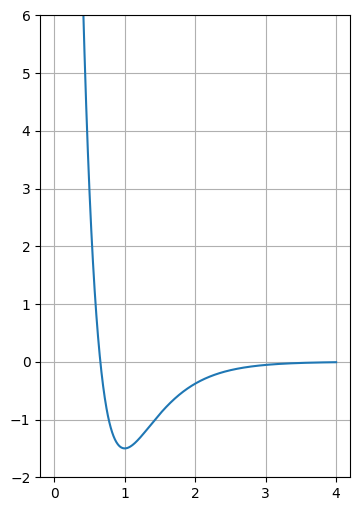

In [3]:
rs = np.linspace(0,4,1000)
fig, ax = plt.subplots(figsize=(4,6))
ax.plot(rs, morsePot(rs))
ax.grid()
ax.set_ylim(-2,6)

In [4]:
class Calculator():
    def potential_energy(self, pos):
        return np.sum(self._V(pdist(pos)))



In [5]:
class Morse(Calculator):
    def _V(self, r):
        return morsePot(r)

In [6]:
morse = Morse()
pos = np.array ([[0 , 0], [3/2 , 0], [0, 1]])
morse.potential_energy(pos)

np.float64(-2.9425037046463043)

In [7]:
class AtomicCluster(AtomicClusterBase):
    @property
    def potential_energy(self):
        return self.calc.potential_energy(self.pos)

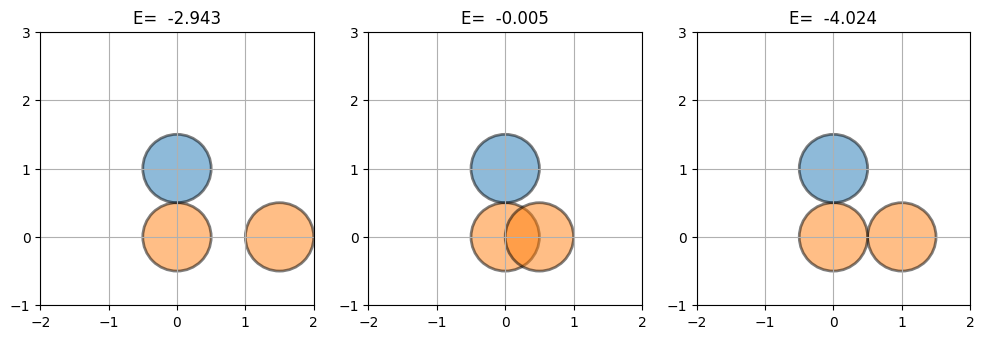

In [8]:
fig , axes = plt. subplots (1,3, figsize =(12 ,4))
cluster0 = AtomicCluster(morse, pos=[[0,0],[3/2 ,0],[0,1]], static =[True,True,False ])
cluster1 = AtomicCluster(morse, pos=[[0,0],[1/2 ,0],[0,1]], static =[True,True,False ])
cluster2 = AtomicCluster(morse, pos=[[1,0],[0 ,0],[0,1]], static =[True,True,False ])
for ax, cluster in zip(axes,[cluster0,cluster1 ,cluster2 ]):
    cluster.draw(ax)
    nice_plot(ax)

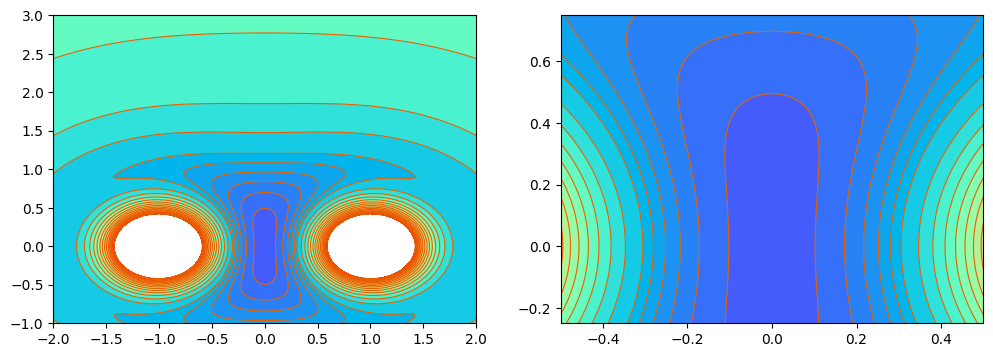

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
pos0 = np.array([[-1.5, 1.5], [1, 0], [-1, 0]], dtype=float)
cluster = AtomicCluster(morse, pos=pos0, static=[False, True, True])

# Left subplot: full view
xs = np.linspace(-2, 2, 100)
ys = np.linspace(-1, 3, 100)
xd, yd = np.meshgrid(xs, ys)
zd = np.zeros(xd.shape)

for i, j in np.ndindex(xd.shape):
    cluster.pos[0] = [xd[i, j], yd[i, j]]
    zd[i, j] = cluster.potential_energy

levels = list(np.arange(-4.5, -2, 0.25)) + list(np.arange(-2, 5.001, 0.5))
axes[0].contourf(xd, yd, zd, levels=levels, cmap="rainbow")
axes[0].contour(xd, yd, zd, levels=levels, colors="#E66100", linewidths=0.8, linestyles="solid")

# Right subplot: zoomed-in saddle region
xs = np.linspace(-0.5, 0.5, 100)
ys = np.linspace(-0.25, 0.75, 100)
xd, yd = np.meshgrid(xs, ys)
zd = np.zeros(xd.shape)

for i, j in np.ndindex(xd.shape):
    cluster.pos[0] = [xd[i, j], yd[i, j]]
    zd[i, j] = cluster.potential_energy

axes[1].contourf(xd, yd, zd, levels=levels, cmap="rainbow")
axes[1].contour(xd, yd, zd, levels=levels, colors="#E66100", linewidths=0.8, linestyles="solid")

In [10]:
class AtomicClusterWithRattleOfFirstAtom(AtomicCluster):
    def rattle_first_atom (self,A=0.01):
        index = 0
        delta_r = A*np.random.randn(2)
        self.pos[index ,:] += delta_r

In [11]:
cluster = AtomicClusterWithRattleOfFirstAtom(morse, pos=pos0, static=[False, True, True])

def monte_carlo_quench(cluster, N, kT=0.15):
    trajectory = [cluster.get_positions()[0].copy()]  # Store initial position of atom 0
    
    for _ in range(N):
        test = cluster.copy()
        test.rattle_first_atom(A=0.01)
        delta_e = test.potential_energy - cluster.potential_energy
        if delta_e < 0 or np.random.rand() < np.exp(-delta_e / kT):
            cluster.set_positions(test.get_positions())
        
        trajectory.append(cluster.get_positions()[0].copy())  # Record position after step
        
    return cluster, np.array(trajectory)

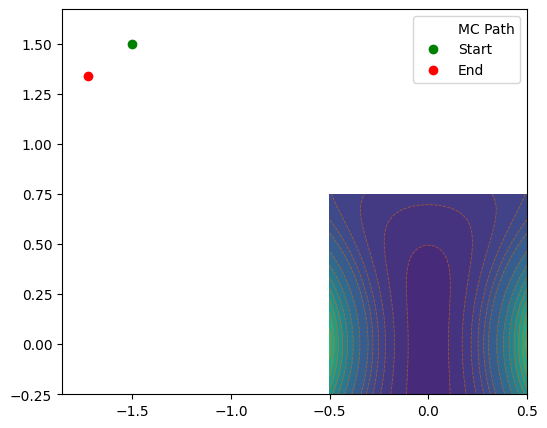

In [12]:
# Initialize cluster and run simulation
cluster = AtomicClusterWithRattleOfFirstAtom(morse, pos=pos0, static=[False, True, True])
final_cluster, traj = monte_carlo_quench(cluster, N=500)

# Plot potential energy background
fig, ax = plt.subplots(figsize=(6, 5))
cf = ax.contourf(xd, yd, zd, levels=levels, cmap="viridis")
ax.contour(xd, yd, zd, levels=levels, colors="#E66100", linewidths=0.6, alpha=0.6)

# Plot Monte Carlo Trajectory
ax.plot(traj[:, 0], traj[:, 1], color="white", linewidth=1, alpha=0.7, label="MC Path")
ax.plot(traj[0, 0], traj[0, 1], "go", markersize=6, label="Start")       # Green start point
ax.plot(traj[-1, 0], traj[-1, 1], "ro", markersize=6, label="End")       # Red end point

ax.legend(loc="upper right")

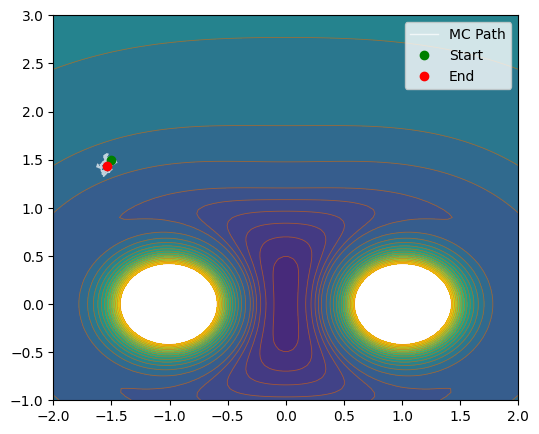

In [13]:
# Initialize cluster and run simulation
cluster = AtomicClusterWithRattleOfFirstAtom(morse, pos=pos0, static=[False, True, True])
final_cluster, traj = monte_carlo_quench(cluster, N=250)

# Use the full-range grid for the background
xs = np.linspace(-2, 2, 100)
ys = np.linspace(-1, 3, 100)
xd, yd = np.meshgrid(xs, ys)
zd = np.zeros(xd.shape)

for i, j in np.ndindex(xd.shape):
    cluster.pos[0] = [xd[i, j], yd[i, j]]
    zd[i, j] = cluster.potential_energy

# Plot background and trajectory
fig, ax = plt.subplots(figsize=(6, 5))
cf = ax.contourf(xd, yd, zd, levels=levels, cmap="viridis")
ax.contour(xd, yd, zd, levels=levels, colors="#E66100", linewidths=0.6, alpha=0.6, linestyles="solid")

ax.plot(traj[:, 0], traj[:, 1],
 color="white", linewidth=1, alpha=0.7, label="MC Path")
ax.plot(traj[0, 0], traj[0, 1], "go", markersize=6, label="Start")
ax.plot(traj[-1, 0], traj[-1, 1], "ro", markersize=6, label="End")

ax.legend(loc="upper right")